<a href="https://colab.research.google.com/github/kathir1406/pyro/blob/main/Heart_Disease_Prediction_Kaggle_Colab_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Heart Disease Prediction — Kaggle + Google Colab

End-to-end workflow: Kaggle CSV download, exploratory data analysis, visualizations, preprocessing, Random Forest training, evaluation, sample prediction, and model export.

**Run:** Upload this notebook to Google Colab, execute cells in order, and upload your Kaggle `kaggle.json` token when prompted. Get the token from Kaggle → Account → Create New Token.

**Medical disclaimer:** Educational demonstration only. This model is not clinically validated and must not be used for diagnosis, screening, treatment, or emergency decisions.

## 1. Install packages

In [ ]:
!pip -q install kaggle pandas numpy scikit-learn matplotlib seaborn joblib

## 2. Configuration

In [ ]:
from pathlib import Path
DATA_DIR = Path('/content/heart_data')
DATA_DIR.mkdir(exist_ok=True)
KAGGLE_DATASET = 'johnsmith88/heart-disease-dataset'  # Change to your Kaggle dataset slug if needed
UPLOAD_CSV_INSTEAD = False  # Set True to upload a CSV instead of using Kaggle API
FEATURES = ['age','sex','cp','trestbps','chol','fbs','restecg','thalach','exang','oldpeak','slope','ca','thal']
TARGET_CANDIDATES = ['target','num','output','condition','heart_disease']
TEST_SIZE, RANDOM_STATE = 0.20, 42

## 3. Download Kaggle dataset or upload CSV

In [ ]:
import os, shutil
from google.colab import files

if UPLOAD_CSV_INSTEAD:
    uploaded = files.upload()
    csvs = [n for n in uploaded if n.lower().endswith('.csv')]
    if not csvs: raise FileNotFoundError('Upload a CSV file.')
    DATA_CSV = DATA_DIR / 'heart.csv'
    shutil.copy(csvs[0], DATA_CSV)
else:
    print('Upload your "kaggle.json" file. Alternatively, if you upload a CSV file directly, we will use it!')
    uploaded = files.upload()

    # Smart Fallback: if the user uploaded a CSV instead of kaggle.json
    csvs = [n for n in uploaded if n.lower().endswith('.csv')]
    if csvs:
        print(f'Detected CSV file "{csvs[0]}" instead of kaggle.json. Using CSV directly.')
        DATA_CSV = DATA_DIR / 'heart.csv'
        shutil.copy(csvs[0], DATA_CSV)
    else:
        if 'kaggle.json' not in uploaded:
            raise FileNotFoundError('Upload kaggle.json from Kaggle account settings or upload a CSV file.')
        kd = Path.home()/'.kaggle'; kd.mkdir(exist_ok=True)
        shutil.copy('kaggle.json', kd/'kaggle.json'); os.chmod(kd/'kaggle.json', 0o600)
        !kaggle datasets download -d {KAGGLE_DATASET} -p {DATA_DIR} --unzip
        found = list(DATA_DIR.rglob('*.csv'))
        if not found: raise FileNotFoundError('No CSV found. Check Kaggle dataset slug.')
        preferred = [p for p in found if 'heart' in p.name.lower() or 'disease' in p.name.lower()]
        DATA_CSV = preferred[0] if preferred else found[0]

print('Using:', DATA_CSV)

Upload your "kaggle.json" file. Alternatively, if you upload a CSV file directly, we will use it!


Saving heart.csv to heart (4).csv
Detected CSV file "heart (4).csv" instead of kaggle.json. Using CSV directly.
Using: /content/heart_data/heart.csv


## 4. Load and inspect data

In [ ]:
import numpy as np, pandas as pd
from IPython.display import display
raw = pd.read_csv(DATA_CSV)
raw.columns = [str(c).strip().lower() for c in raw.columns]
print('Shape:', raw.shape, '\\nColumns:', raw.columns.tolist())
display(raw.head())
display(raw.describe(include='all').T)

Shape: (920, 16) \nColumns: ['id', 'age', 'sex', 'dataset', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalch', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'num']


,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
0,1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
1,2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2
2,3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
3,4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0
4,5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,920.0,NaN,NaN,NaN,460.5,265.725422,1.0,230.75,460.5,690.25,920.0
age,920.0,NaN,NaN,NaN,53.51087,9.424685,28.0,47.0,54.0,60.0,77.0
sex,920,2,Male,726,NaN,NaN,NaN,NaN,NaN,NaN,NaN
dataset,920,4,Cleveland,304,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cp,920,4,asymptomatic,496,NaN,NaN,NaN,NaN,NaN,NaN,NaN
trestbps,861.0,NaN,NaN,NaN,132.132404,19.06607,0.0,120.0,130.0,140.0,200.0
chol,890.0,NaN,NaN,NaN,199.130337,110.78081,0.0,175.0,223.0,268.0,603.0
fbs,830,2,False,692,NaN,NaN,NaN,NaN,NaN,NaN,NaN
restecg,918,3,normal,551,NaN,NaN,NaN,NaN,NaN,NaN,NaN
thalch,865.0,NaN,NaN,NaN,137.545665,25.926276,60.0,120.0,140.0,157.0,202.0


## 5. Clean and prepare features

In [ ]:
# Map common column name variations/misspellings (e.g. thalch -> thalach)
if 'thalch' in raw.columns and 'thalach' not in raw.columns:
    raw = raw.rename(columns={'thalch': 'thalach'})

target_col = next((c for c in TARGET_CANDIDATES if c in raw.columns), None)
if target_col is None: raise ValueError(f'No target column found. Available: {raw.columns.tolist()}')
missing = [c for c in FEATURES if c not in raw.columns]
if missing: raise ValueError(f'Missing expected UCI feature columns: {missing}. Check dataset schema/encoding.')
df = raw[FEATURES + [target_col]].replace(['?','NA','N/A',''], np.nan).copy()
for c in df.columns: df[c] = pd.to_numeric(df[c], errors='coerce')
df = df.dropna(subset=[target_col])
X = df[FEATURES].copy()
y = (df[target_col] > 0).astype(int)  # UCI labels 0 vs 1–4
if y.nunique() != 2: raise ValueError('Need both target classes after cleaning.')
print('Cleaned shape:', df.shape)
print('Missing feature values:', int(X.isna().sum().sum()))
display(y.value_counts().rename_axis('target').to_frame('count'))

Cleaned shape: (920, 14)
Missing feature values: 5562


,count
target,
1,509
0,411


## 6. Exploratory data analysis and visualizations

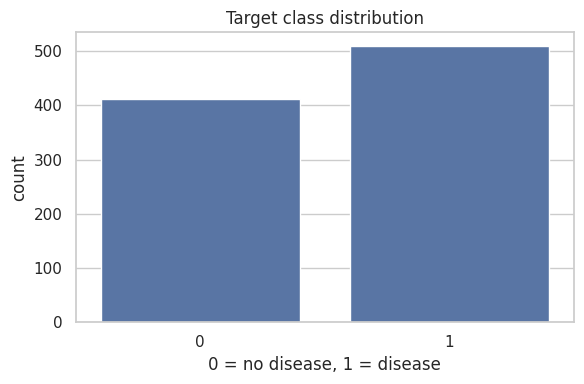

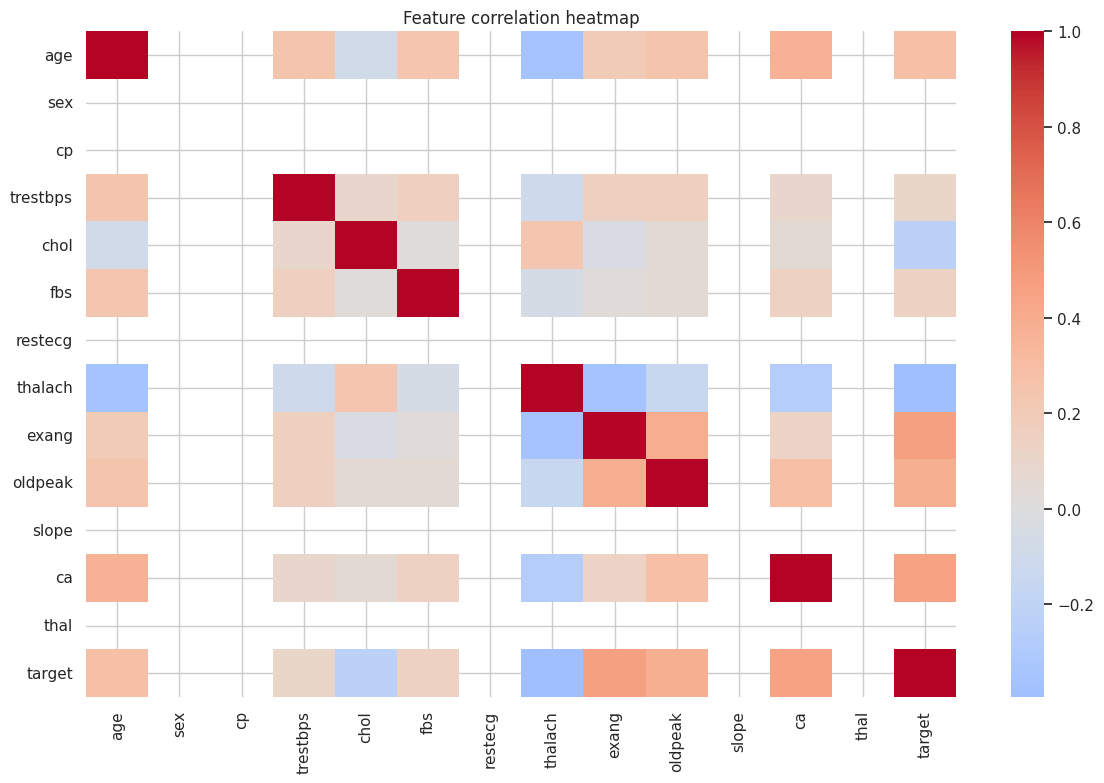

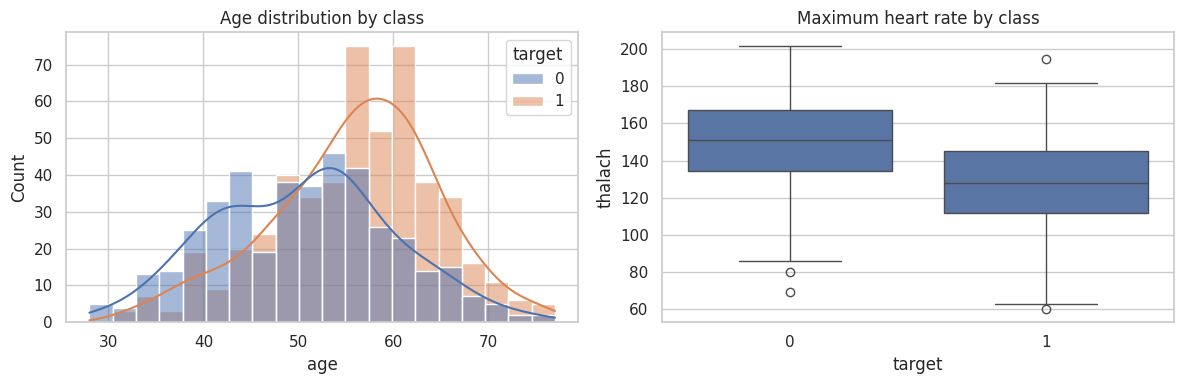

In [ ]:
import matplotlib.pyplot as plt, seaborn as sns
sns.set_theme(style='whitegrid')
plt.figure(figsize=(6,4))
sns.countplot(x=y)
plt.title('Target class distribution'); plt.xlabel('0 = no disease, 1 = disease'); plt.tight_layout(); plt.show()

corr = X.copy(); corr['target'] = y
plt.figure(figsize=(12,8))
sns.heatmap(corr.corr(numeric_only=True), cmap='coolwarm', center=0)
plt.title('Feature correlation heatmap'); plt.tight_layout(); plt.show()

plot_df = X.copy(); plot_df['target'] = y.values
fig, ax = plt.subplots(1,2,figsize=(12,4))
sns.histplot(data=plot_df,x='age',hue='target',bins=20,kde=True,ax=ax[0])
ax[0].set_title('Age distribution by class')
sns.boxplot(data=plot_df,x='target',y='thalach',ax=ax[1])
ax[1].set_title('Maximum heart rate by class')
plt.tight_layout(); plt.show()

## 7. Split data, impute missing values, and scale

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y
)
imputer = SimpleImputer(strategy='median')
X_train_i = imputer.fit_transform(X_train)
X_test_i = imputer.transform(X_test)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train_i)
X_test_s = scaler.transform(X_test_i)
print('Train:', len(X_train), 'Test:', len(X_test))

Train: 736 Test: 184


/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['sex' 'cp' 'restecg' 'slope' 'thal']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['sex' 'cp' 'restecg' 'slope' 'thal']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


## 8. Train Random Forest

In [ ]:
from sklearn.ensemble import RandomForestClassifier
model = RandomForestClassifier(
    n_estimators=500, min_samples_leaf=2, class_weight='balanced',
    random_state=RANDOM_STATE, n_jobs=-1
)
model.fit(X_train_s, y_train)
y_pred = model.predict(X_test_s)
positive_index = list(model.classes_).index(1)
y_proba = model.predict_proba(X_test_s)[:, positive_index]
print('Training complete.')

Training complete.


## 9. Evaluate: accuracy, precision, recall, F1, classification report, confusion matrix

Accuracy:  0.804
Precision: 0.817
Recall:    0.833
F1-score:  0.825
\nClassification report:\n               precision    recall  f1-score   support

           0       0.79      0.77      0.78        82
           1       0.82      0.83      0.83       102

    accuracy                           0.80       184
   macro avg       0.80      0.80      0.80       184
weighted avg       0.80      0.80      0.80       184



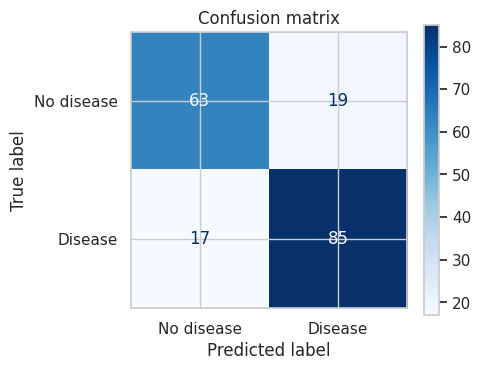

In [ ]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, ConfusionMatrixDisplay)
accuracy = accuracy_score(y_test,y_pred)
precision = precision_score(y_test,y_pred,zero_division=0)
recall = recall_score(y_test,y_pred,zero_division=0)
f1 = f1_score(y_test,y_pred,zero_division=0)
print(f'Accuracy:  {accuracy:.3f}')
print(f'Precision: {precision:.3f}')
print(f'Recall:    {recall:.3f}')
print(f'F1-score:  {f1:.3f}')
print('\\nClassification report:\\n', classification_report(y_test,y_pred,zero_division=0))
fig, ax = plt.subplots(figsize=(5,4))
ConfusionMatrixDisplay.from_predictions(y_test,y_pred,display_labels=['No disease','Disease'],cmap='Blues',ax=ax)
plt.title('Confusion matrix'); plt.tight_layout(); plt.show()

## 10. ROC curve and feature importance

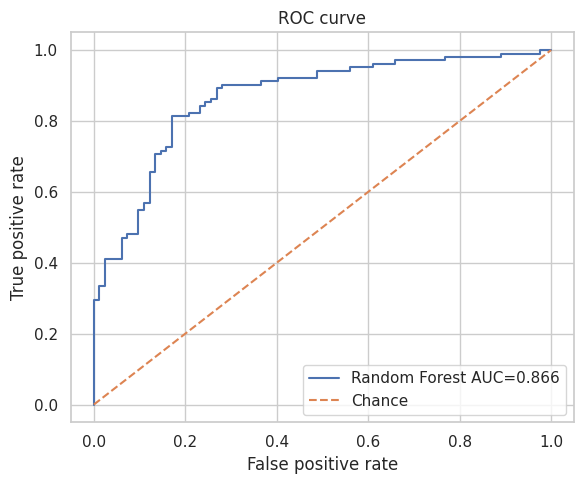

ROC-AUC: 0.866


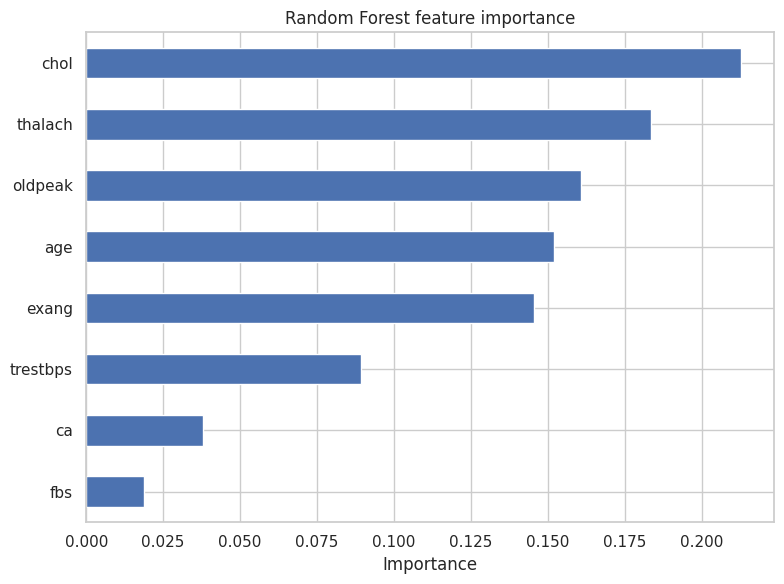

In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score
fpr,tpr,_ = roc_curve(y_test,y_proba)
auc = roc_auc_score(y_test,y_proba)
plt.figure(figsize=(6,5))
plt.plot(fpr,tpr,label=f'Random Forest AUC={auc:.3f}')
plt.plot([0,1],[0,1],'--',label='Chance')
plt.xlabel('False positive rate'); plt.ylabel('True positive rate')
plt.title('ROC curve'); plt.legend(); plt.tight_layout(); plt.show()
print('ROC-AUC:', round(auc,3))

# Dynamically filter FEATURES to match only the columns that were not skipped by the imputer
retained_features = [f for f, is_skipped in zip(FEATURES, imputer.statistics_) if not np.isnan(is_skipped)]

importances = pd.Series(model.feature_importances_, index=retained_features).sort_values()
plt.figure(figsize=(8,6)); importances.plot(kind='barh')
plt.title('Random Forest feature importance'); plt.xlabel('Importance')
plt.tight_layout(); plt.show()

## 11. Predict an illustrative sample patient

In [ ]:
# Illustrative feature values only; not a real patient or medical advice.
sample = pd.DataFrame([{
    'age':54,'sex':1,'cp':2,'trestbps':130,'chol':240,'fbs':0,
    'restecg':1,'thalach':150,'exang':0,'oldpeak':1.0,'slope':2,'ca':0,'thal':2
}], columns=FEATURES)
sample_s = scaler.transform(imputer.transform(sample))
pred = int(model.predict(sample_s)[0])
prob = float(model.predict_proba(sample_s)[0,positive_index]*100)
print('Predicted class:', pred, '(0 or 1 dataset class)')
print(f'Model positive-class probability: {prob:.1f}%')
print('Not an individual clinical risk estimate.')

/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['sex' 'cp' 'restecg' 'slope' 'thal']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


Predicted class: 0 (0 or 1 dataset class)
Model positive-class probability: 26.2%
Not an individual clinical risk estimate.


## 12. Save model artifacts and download ZIP

In [ ]:
import joblib, shutil
ARTIFACTS = Path('/content/heart_model_artifacts')
ARTIFACTS.mkdir(exist_ok=True)
joblib.dump(model,ARTIFACTS/'heart_model.joblib')
joblib.dump(imputer,ARTIFACTS/'imputer.joblib')
joblib.dump(scaler,ARTIFACTS/'scaler.joblib')
joblib.dump(FEATURES,ARTIFACTS/'features.joblib')
joblib.dump({'accuracy':float(accuracy),'precision':float(precision),
             'recall':float(recall),'f1':float(f1),'roc_auc':float(auc)},
            ARTIFACTS/'metrics.joblib')
archive = shutil.make_archive('/content/heart_model_artifacts','zip',ARTIFACTS)
print('Created:',archive)
files.download(archive)

Created: /content/heart_model_artifacts.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Notes and troubleshooting

- Default Kaggle slug: `johnsmith88/heart-disease-dataset`. Change `KAGGLE_DATASET` if you use another dataset.
- If Kaggle access fails, check the slug, accept any dataset terms on Kaggle, and ensure the API token is valid.
- You can bypass Kaggle API by setting `UPLOAD_CSV_INSTEAD = True` in the configuration cell.
- The notebook expects UCI-style feature names and encodings. Verify the dataset's data dictionary; do not map unrelated columns by guesswork.
- The original UCI target values 0–4 are binarized as 0 vs greater than 0.
- A random holdout score on a small historical dataset does not prove clinical validity. External validation, calibration, subgroup analysis, and clinical/regulatory review are needed before any real-world use.